# Воронка покупок и A/A/B-тест мобильного приложения

**Учебный проект Яндекс Практикума · продуктовая аналитика**

Где пользователи приложения для покупки продуктов чаще всего прерывают путь к оплате? По журналу событий я восстановил последовательность действий каждого пользователя. Затем проверил, изменилось ли поведение покупателей после смены шрифта. В эксперименте участвовали две контрольные группы и одна группа с новым оформлением.

### Содержание

1. [Загрузка и общая информация](#section-1)
2. [Подготовка данных](#section-2)
3. [Качество лога и выбор периода](#section-3)
4. [Воронка событий](#section-4)
5. [A/A/B-эксперимент](#section-5)
6. [Выводы и решение](#section-6)

### Основные результаты

| Вопрос | Ответ |
|:--|:--|
| На каких данных основан анализ? | 240 887 событий и 7 534 пользователя с 1 по 7 августа 2019 года. Конец выгрузки — 7 августа, 21:15:17 UTC. |
| Где основная потеря? | Между главным экраном и предложениями: разность охватов — 38,1%; в последовательной воронке — 39,9%. |
| Сколько пользователей дошло до покупки? | Отношение охватов оплаты и главного экрана — 47,7%; полная наблюдаемая последовательность из четырёх событий — у 41,6% начавших. |
| Помог ли новый шрифт? | Статистически значимых различий не обнаружено ни в одной из 20 проверок. |
| Насколько точна оценка оплаты? | Новый шрифт против объединённого контроля: −0,64 п.п.; индивидуальный 95% ДИ [−3,02; +1,75] п.п. |

Отсутствие обнаруженного различия не доказывает равенство шрифтов или отсутствие любого влияния.

<a id="section-1"></a>
## 1. Загрузка и общая информация

Источник — учебный журнал событий приложения за июль и август 2019 года. Для основной части анализа использую полный период с 1 по 7 августа.

Одна строка — зарегистрированное событие. `DeviceIDHash` используется как идентификатор пользователя; технически это хеш устройства, поэтому уникальный идентификатор не обязательно равен уникальному человеку.

| Исходное поле | Содержание |
|:--|:--|
| `EventName` | Тип события. |
| `DeviceIDHash` | Идентификатор пользователя / устройства. |
| `EventTimestamp` | Время события в секундах Unix. |
| `ExpId` | 246 и 247 — старый шрифт; 248 — новый шрифт. |

Для повторного запуска нужен исходный файл курса `logs_exp.csv`. Ноутбук читает его из своей папки, подпапки `data` или каталога `/datasets`. Графики и таблицы сохранены в результатах ячеек.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from IPython.display import display

pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 60)
pd.set_option('display.float_format', '{:,.3f}'.format)

COLORS = {
    'ink': '#18324A', 'blue': '#3267A7', 'teal': '#168B89',
    'orange': '#D48235', 'red': '#B94A48', 'gray': '#8898A6',
    'light': '#E5ECF2', 'purple': '#8566A8',
}
mpl.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10.5,
    'figure.figsize': (11.5, 4.8), 'figure.dpi': 130, 'savefig.dpi': 150,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'text.color': COLORS['ink'], 'axes.labelcolor': COLORS['ink'],
    'axes.titleweight': 'bold', 'axes.titlesize': 13,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#CBD5DF', 'axes.grid': True,
    'grid.color': '#E5ECF2', 'grid.alpha': 0.8,
    'xtick.color': '#52677A', 'ytick.color': '#52677A',
    'axes.axisbelow': True, 'legend.frameon': False,
})

print(f'Python {sys.version.split()[0]} | pandas {pd.__version__} | NumPy {np.__version__}')

Python 3.12.14 | pandas 3.0.1 | NumPy 2.5.5


In [2]:
def table(frame, formats=None, caption=None):
    """Единое оформление таблиц; исходные числа остаются числовыми."""
    styled = (frame.style
              .format(formats or {}, na_rep='—')
              .set_table_styles([
                  {'selector': 'th', 'props': [('background', '#EDF3F8'),
                                               ('color', '#18324A'), ('text-align', 'left')]},
                  {'selector': 'td', 'props': [('padding', '7px 11px'),
                                               ('border-bottom', '1px solid #E5ECF2')]},
                  {'selector': 'caption', 'props': [('caption-side', 'top'),
                                                    ('text-align', 'left'),
                                                    ('font-weight', '600'), ('padding', '8px 0')]},
              ]))
    if caption:
        styled = styled.set_caption(caption)
    display(styled)


def barh(series, ax, title, xlabel, color=None, percent=False, integer=False):
    """Горизонтальная диаграмма с нулевой базой и подписями значений."""
    series = series.sort_values(ascending=True)
    values = series.to_numpy(dtype=float)
    colors = color if color is not None else COLORS['blue']
    ax.barh(series.index.astype(str), values, color=colors, height=0.68)
    ax.set(title=title, xlabel=xlabel)
    ax.grid(axis='y', visible=False)
    ax.set_xlim(0, max(values) * 1.22 if len(values) and max(values) else 1)
    for i, value in enumerate(values):
        label = f'{value:.1f}%' if percent else (f'{value:,.0f}' if integer else f'{value:.2f}')
        ax.text(value + max(values) * 0.018, i, label, va='center', fontsize=9)


def finish(fig):
    fig.tight_layout(pad=1.5)
    plt.show()

In [3]:
paths = [Path('logs_exp.csv'), Path('data/logs_exp.csv'), Path('/datasets/logs_exp.csv')]
data_path = next((p for p in paths if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError('Положите logs_exp.csv рядом с ноутбуком или в data/.')

# Файл имеет расширение CSV, но разделитель — табуляция.
# Идентификаторы читаем строками, сохраняя все цифры без перехода через float.
raw = pd.read_csv(data_path, sep='\t', dtype={'DeviceIDHash': 'string'})
print(f'Строк: {len(raw):,}; столбцов: {raw.shape[1]}; файл: {data_path.name}.')
raw.info()

Строк: 244,126; столбцов: 4; файл: logs_exp.csv.
<class 'pandas.DataFrame'>
RangeIndex: 244126 entries, 0 to 244125
Data columns (total 4 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   EventName       244126 non-null  str   
 1   DeviceIDHash    244126 non-null  string
 2   EventTimestamp  244126 non-null  int64 
 3   ExpId           244126 non-null  int64 
dtypes: int64(2), str(1), string(1)
memory usage: 7.5 MB


В файле **244 126 строк и 4 столбца**. Текстовые поля представлены названием события и идентификатором, время и эксперимент — целыми числами. Далее проверим пропуски, дубли и принадлежность пользователей к группам.

<a id="section-2"></a>
## 2. Подготовка данных

### 2.1. Пропуски, типы и повторяющиеся строки

In [4]:
quality = pd.DataFrame({'Тип': raw.dtypes.astype(str),
                        'Пропусков': raw.isna().sum(),
                        'Доля пропусков': raw.isna().mean()})
table(quality, {'Пропусков': '{:.0f}', 'Доля пропусков': '{:.1%}'}, 'Исходное качество данных')
duplicate_count = int(raw.duplicated().sum())
print(f'Полных дубликатов: {duplicate_count} ({duplicate_count / len(raw):.3%}).')

,Тип,Пропусков,Доля пропусков
EventName,str,0,0.0%
DeviceIDHash,string,0,0.0%
EventTimestamp,int64,0,0.0%
ExpId,int64,0,0.0%


Полных дубликатов: 413 (0.169%).


Пропусков нет. Найдено **413 полных дубликатов** — совпадают событие, пользователь, секунда и группа. Для анализа считаем их техническими повторениями и оставляем одну копию. Без отдельного идентификатора события нельзя окончательно отличить дубль от двух одинаковых действий в одну секунду; на факт наличия события у пользователя такое удаление не влияет.

Повторные действия пользователя в другое время сохраняем. Удалять дубли только по пользователю или по паре «пользователь — событие» из общего лога нельзя: это исказило бы активность.

Столбцы переименуем. Unix-время переведём в timezone-aware `datetime`, отдельно добавим дату. Используем **UTC** как явно заданную техническую шкалу; локальный часовой пояс аудитории неизвестен, поэтому время не переводим в московское автоматически.

In [5]:
logs = raw.rename(columns={
    'EventName': 'event_name', 'DeviceIDHash': 'user_id',
    'EventTimestamp': 'event_timestamp', 'ExpId': 'experiment_id',
}).drop_duplicates().copy()

logs['event_time'] = pd.to_datetime(logs['event_timestamp'], unit='s', utc=True)
logs['event_date'] = logs['event_time'].dt.date

assert logs[['event_name', 'user_id', 'event_timestamp', 'experiment_id']].notna().all().all()
assert set(logs['experiment_id'].unique()) == {246, 247, 248}
assert not logs.duplicated().any()

table(pd.DataFrame({'Тип после подготовки': logs.dtypes.astype(str),
                     'Пропусков': logs.isna().sum()}), {'Пропусков': '{:.0f}'})
print(f'После удаления дублей: {len(logs):,} событий.')

,Тип после подготовки,Пропусков
event_name,str,0
user_id,string,0
event_timestamp,int64,0
experiment_id,int64,0
event_time,"datetime64[s, UTC]",0
event_date,object,0


После удаления дублей: 243,713 событий.


`event_time` содержит дату, время и UTC; `event_date` — календарную дату для группировок. Фильтрация ниже выполняется по `event_time`, чтобы не смешивать Python `date` и pandas `Timestamp`. Идентификатор остаётся строковым, а номер группы и исходный timestamp — целочисленными: арифметика над идентификаторами не требуется.

<a id="section-3"></a>
## 3. Качество лога и выбор периода

### 3.1. Сколько событий и пользователей в файле?

In [6]:
user_activity_all = logs.groupby('user_id').size()
overview = pd.DataFrame({'Значение': [
    f'{len(raw):,}', f'{len(logs):,}', f'{logs["user_id"].nunique():,}',
    f'{user_activity_all.mean():.2f}', f'{user_activity_all.median():.0f}',
    str(logs['event_time'].min()), str(logs['event_time'].max()),
]}, index=['Строк до удаления дублей', 'Событий без дублей', 'Уникальных пользователей',
           'Событий на пользователя: среднее', 'Событий на пользователя: медиана',
           'Первое событие, UTC', 'Последнее событие, UTC'])
table(overview, caption='Объём лога до временного отсечения')

,Значение
Строк до удаления дублей,"244,126"
Событий без дублей,"243,713"
Уникальных пользователей,"7,551"
Событий на пользователя: среднее,32.28
Событий на пользователя: медиана,20
"Первое событие, UTC",2019-07-25 04:43:36+00:00
"Последнее событие, UTC",2019-08-07 21:15:17+00:00


После удаления дублей остаются **243 713 событий** и **7 551 пользователь**. В среднем на пользователя приходится **32,28 события**. Среднее число действий может быть выше типичной активности из-за небольшого числа очень активных устройств; распределение изучим на выбранном рабочем периоде.

Полный диапазон — с **25 июля 2019, 04:43:36 UTC** до **7 августа 2019, 21:15:17 UTC**. Наличие дат ещё не гарантирует одинаковую полноту их логирования.

### 3.2. Полнота данных по времени и группам

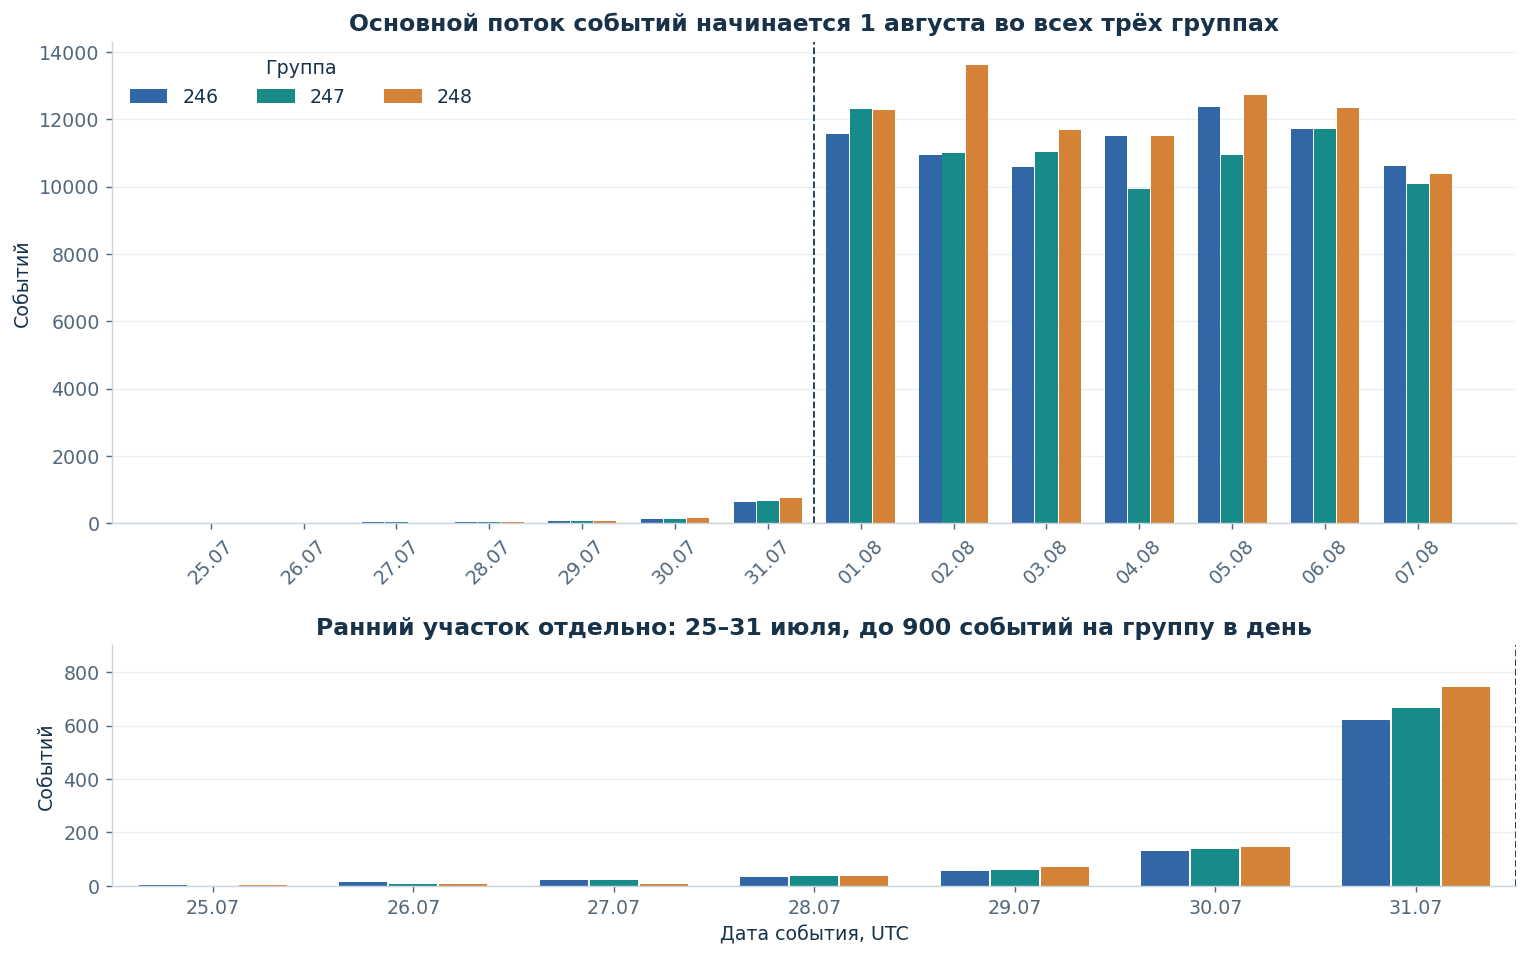

experiment_id,246 — контроль,247 — контроль,248 — новый шрифт
event_date,,,
25.07.2019,4,1,4
26.07.2019,14,8,9
27.07.2019,24,23,8
28.07.2019,33,36,36
29.07.2019,55,58,71
30.07.2019,129,138,145
31.07.2019,620,664,746
01.08.2019,11561,12306,12274
02.08.2019,10946,10990,13618


In [7]:
GROUP_COLORS = {246: COLORS['blue'], 247: COLORS['teal'], 248: COLORS['orange']}
daily = (logs.groupby(['event_date', 'experiment_id']).size()
         .unstack('experiment_id', fill_value=0).reindex(columns=[246, 247, 248]))
daily.index = pd.to_datetime(daily.index)
positions = np.arange(len(daily))
fig, axes = plt.subplots(2, 1, figsize=(12, 7.6), sharex=False,
                         gridspec_kw={'height_ratios': [2, 1]})
for offset, group in zip([-0.25, 0, 0.25], [246, 247, 248]):
    for ax in axes:
        ax.bar(positions + offset, daily[group], width=0.24,
               color=GROUP_COLORS[group], label=f'{group}')
cut_position = int(np.flatnonzero(daily.index == pd.Timestamp('2019-08-01'))[0])
for ax in axes:
    ax.axvline(cut_position - 0.5, color=COLORS['ink'], linestyle='--', linewidth=1)
    ax.set_ylabel('Событий')
    ax.grid(axis='x', visible=False)
axes[0].set_title('Основной поток событий начинается 1 августа во всех трёх группах')
axes[0].legend(title='Группа', ncol=3, loc='upper left')
axes[0].set_xticks(positions, daily.index.strftime('%d.%m'), rotation=45)
axes[1].set(ylim=(0, 900), xlim=(-0.5, cut_position - 0.5),
            title='Ранний участок отдельно: 25–31 июля, до 900 событий на группу в день',
            xlabel='Дата события, UTC')
axes[1].set_xticks(positions[:cut_position], daily.index[:cut_position].strftime('%d.%m'))
finish(fig)
table(daily.rename(columns={246: '246 — контроль', 247: '247 — контроль', 248: '248 — новый шрифт'})
      .set_axis(daily.index.strftime('%d.%m.%Y')), caption='События по датам и группам')

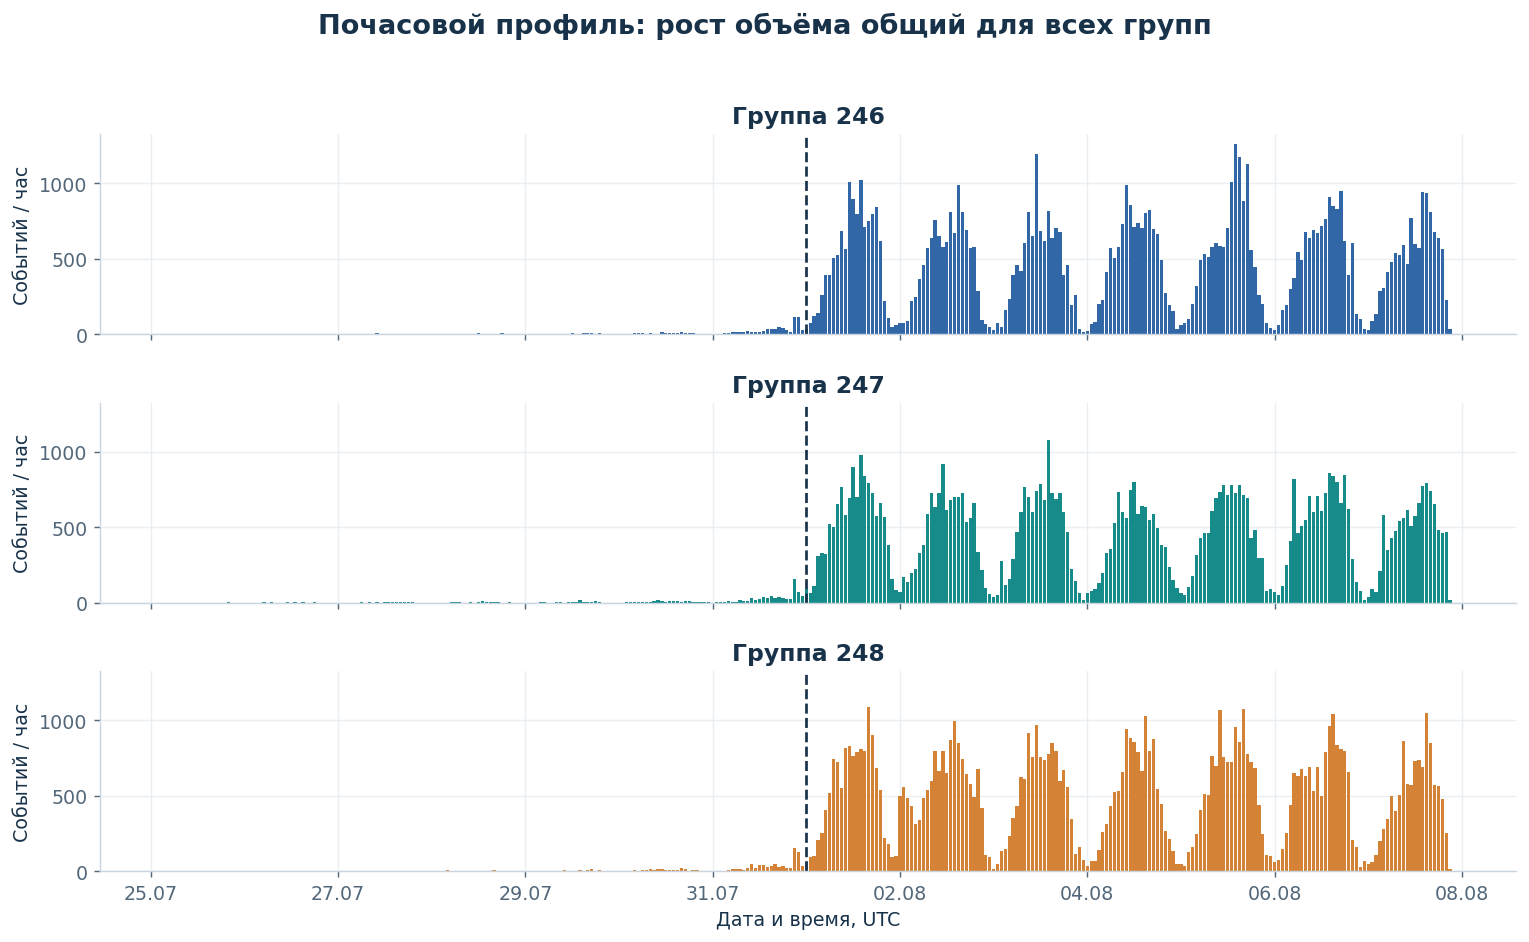

In [8]:
hourly = (logs.set_index('event_time').groupby('experiment_id').resample('h').size()
          .unstack(0, fill_value=0).reindex(columns=[246, 247, 248]).fillna(0))
fig, axes = plt.subplots(3, 1, figsize=(12, 7.2), sharex=True, sharey=True)
for ax, group in zip(axes, [246, 247, 248]):
    ax.bar(hourly.index, hourly[group], width=0.035, color=GROUP_COLORS[group])
    ax.axvline(pd.Timestamp('2019-08-01', tz='UTC'), color=COLORS['ink'], linestyle='--')
    ax.set(title=f'Группа {group}', ylabel='Событий / час')
axes[-1].xaxis.set_major_locator(mdates.DayLocator(interval=2))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%d.%m', tz='UTC'))
axes[-1].set_xlabel('Дата и время, UTC')
fig.suptitle('Почасовой профиль: рост объёма общий для всех групп',
             fontsize=15, fontweight='bold', y=1.01)
finish(fig)

До 1 августа наблюдаются единицы, десятки и сотни событий в день, затем — десятки тысяч. Изменение видно **во всех трёх группах**; это согласуется с неполнотой раннего участка, а не с различием шрифтов. По одному логу нельзя доказать причину: например, это могут быть поздно поступившие старые события.

Рабочий период выбираем **с 1 по 7 августа 2019 года**. Это наиболее представительный участок лога, но не семь доказанно полных UTC-суток: выгрузка заканчивается **7 августа в 21:15:17 UTC**, последний день обрезан. Воронку и эксперимент считаем на одном и том же окне; неполноту конца учитываем как ограничение. Фильтрацию по времени задаём один раз и далее не меняем.

In [9]:
START = pd.Timestamp('2019-08-01 00:00:00', tz='UTC')
END_EXCLUSIVE = pd.Timestamp('2019-08-08 00:00:00', tz='UTC')
analysis = logs.loc[logs['event_time'].ge(START) & logs['event_time'].lt(END_EXCLUSIVE)].copy()

lost_events = len(logs) - len(analysis)
lost_users = logs['user_id'].nunique() - analysis['user_id'].nunique()
losses = pd.DataFrame({
    'До отсечения': [len(logs), logs['user_id'].nunique()],
    'После отсечения': [len(analysis), analysis['user_id'].nunique()],
    'Потеря': [lost_events, lost_users],
    'Доля потерь': [lost_events / len(logs), lost_users / logs['user_id'].nunique()],
}, index=['События', 'Пользователи'])
table(losses, {'До отсечения': '{:,.0f}', 'После отсечения': '{:,.0f}',
                'Потеря': '{:,.0f}', 'Доля потерь': '{:.2%}'}, 'Цена временного отсечения')
print('Фактическое окно:', analysis['event_time'].min(), '—', analysis['event_time'].max())

,До отсечения,После отсечения,Потеря,Доля потерь
События,"243,713","240,887","2,826",1.16%
Пользователи,"7,551","7,534",17,0.23%


Фактическое окно: 2019-08-01 00:07:28+00:00 — 2019-08-07 21:15:17+00:00


Удалены **2 826 событий (1,16%)** и **17 пользователей (0,23%)**, которые больше не встречаются в рабочем окне. У пользователей, присутствующих и до, и после границы, удаляются только ранние события. Это небольшие потери относительно общего лога, однако сами по себе они не доказывают отсутствие смещения.

### 3.3. Группы и активность пользователей

Пользователей, встречающихся в нескольких группах: 0


,Пользователей,Событий,Доля пользователей,Событий на пользователя
experiment_id,,,,
246,"2,484","79,302",32.97%,31.93
247,"2,513","77,022",33.36%,30.65
248,"2,537","84,563",33.67%,33.33


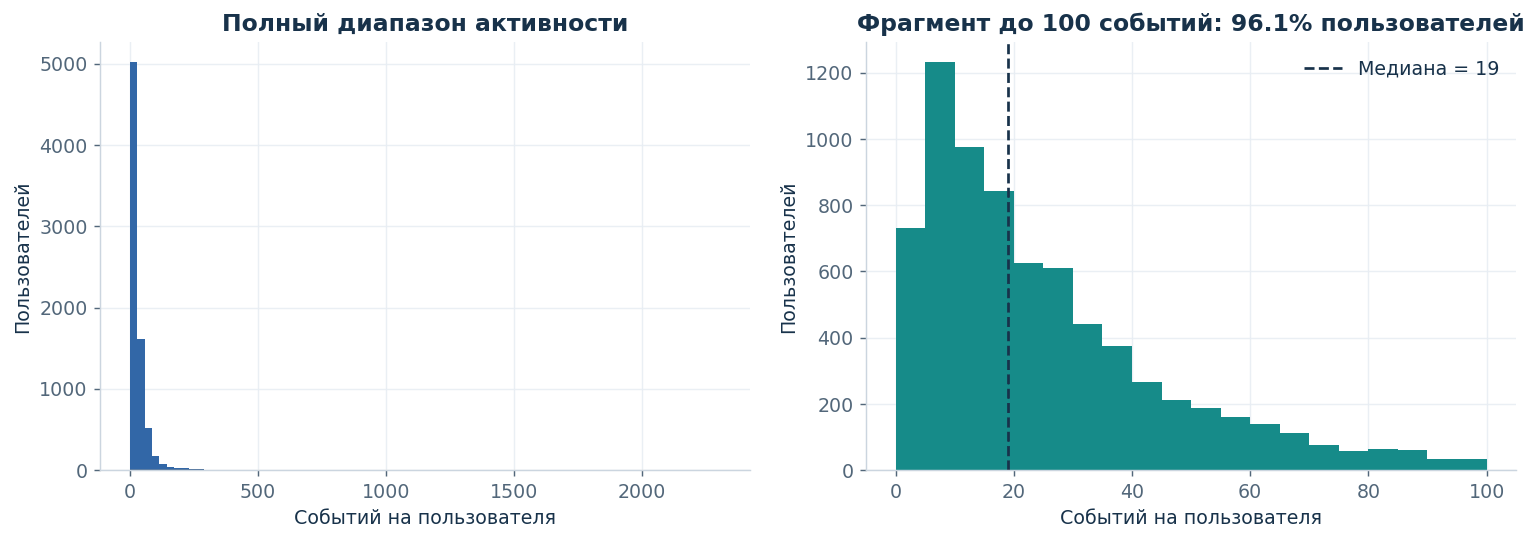

,Событий на пользователя
count,7534.00
mean,31.97
std,65.09
min,1.00
25%,9.00
50%,19.00
75%,37.00
95%,88.00
99%,201.01
max,2307.00


In [10]:
# Проверяем закрепление группы на всём доступном периоде, до отсечения.
groups_per_user = logs.groupby('user_id')['experiment_id'].nunique()
overlap_users = groups_per_user[groups_per_user > 1]
assert overlap_users.empty

group_summary = analysis.groupby('experiment_id').agg(
    users=('user_id', 'nunique'), events=('event_name', 'size'))
group_summary['user_share'] = group_summary['users'] / group_summary['users'].sum()
group_summary['events_per_user'] = group_summary['events'] / group_summary['users']
assert set(group_summary.index) == {246, 247, 248}
print('Пользователей, встречающихся в нескольких группах:', len(overlap_users))
table(group_summary.rename(columns={
    'users': 'Пользователей', 'events': 'Событий', 'user_share': 'Доля пользователей',
    'events_per_user': 'Событий на пользователя',
}), {'Пользователей': '{:,.0f}', 'Событий': '{:,.0f}', 'Доля пользователей': '{:.2%}',
     'Событий на пользователя': '{:.2f}'}, 'Все три группы присутствуют в рабочем окне')

activity = analysis.groupby('user_id').size()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].hist(activity, bins=80, color=COLORS['blue'])
axes[0].set(title='Полный диапазон активности', xlabel='Событий на пользователя', ylabel='Пользователей')
zoom = activity[activity <= 100]
axes[1].hist(zoom, bins=np.arange(0, 105, 5), color=COLORS['teal'])
axes[1].axvline(activity.median(), color=COLORS['ink'], linestyle='--', label='Медиана = 19')
axes[1].set(title=f'Фрагмент до 100 событий: {len(zoom) / len(activity):.1%} пользователей',
            xlabel='Событий на пользователя', ylabel='Пользователей')
axes[1].legend()
finish(fig)
table(activity.describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).to_frame('Событий на пользователя'),
      {'Событий на пользователя': '{:.2f}'}, 'Распределение активности, 1–7 августа')

В рабочем окне **2 484 / 2 513 / 2 537 пользователей** в группах 246 / 247 / 248. Пересечений идентификаторов между группами нет даже на полном логе. Размеры групп близки, а временные профили похожи. Это полезные проверки, но они не доказывают корректность всей рандомизации; целевые доли распределения и журнал назначения групп не предоставлены.

Средняя активность — **31,97 события**, медиана — **19**, максимум — **2 307**. Для эксперимента считаем бинарный факт совершения события **одним пользователем**, поэтому активный пользователь не получает больший вес из-за повторных действий. Пользователей с высокой активностью не удаляем без оснований считать их ботами.

<a id="section-4"></a>
## 4. Воронка событий

### 4.1. Частота событий и охват пользователей

Разделяем число действий и число пользователей. Для охвата каждый пользователь считается один раз в рамках события, сколько бы раз он его ни повторял. Знаменатель — все **7 534 пользователя рабочего окна**.

,Событий,Пользователей,Доля событий,Доля пользователей
event_name,,,,
MainScreenAppear,"117,328","7,419",48.7%,98.5%
OffersScreenAppear,"46,333","4,593",19.2%,61.0%
CartScreenAppear,"42,303","3,734",17.6%,49.6%
PaymentScreenSuccessful,"33,918","3,539",14.1%,47.0%
Tutorial,"1,005",840,0.4%,11.1%


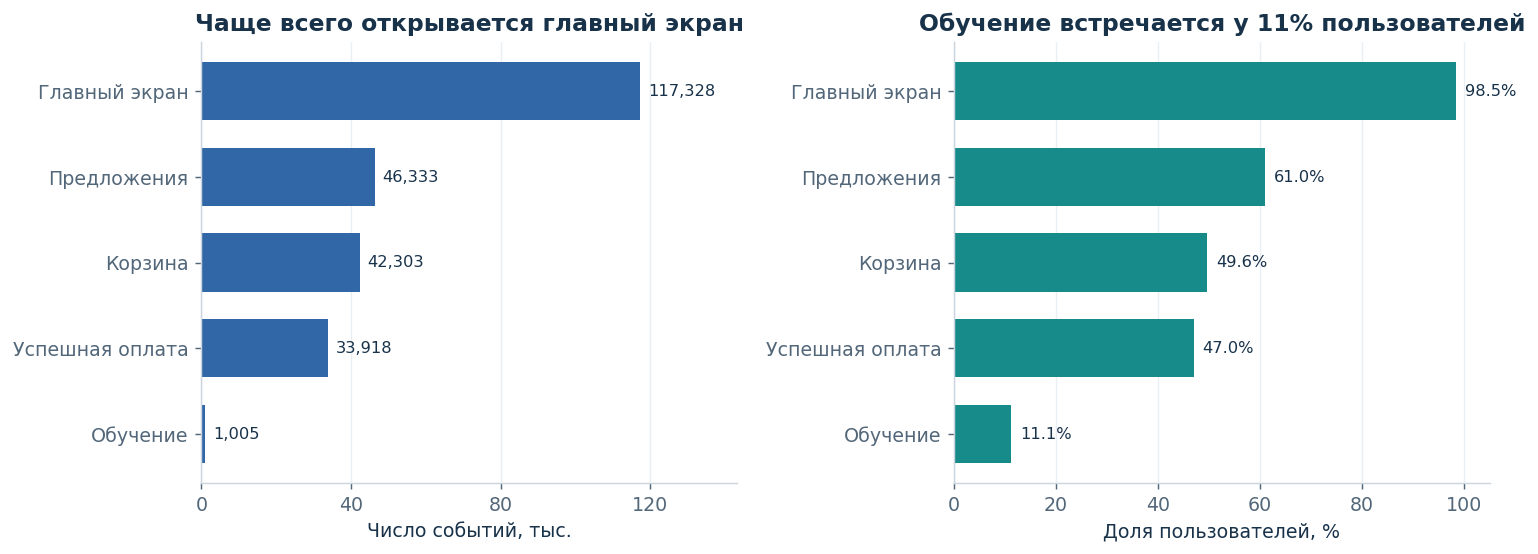

,Пользователей,Доля пользователей
event_name,,
MainScreenAppear,"7,419",98.47%
OffersScreenAppear,"4,593",60.96%
CartScreenAppear,"3,734",49.56%
PaymentScreenSuccessful,"3,539",46.97%
Tutorial,840,11.15%


In [11]:
event_summary = (analysis.groupby('event_name').agg(
    events=('user_id', 'size'), users=('user_id', 'nunique'))
    .sort_values('events', ascending=False))
event_summary['event_share'] = event_summary['events'] / len(analysis)
event_summary['user_share'] = event_summary['users'] / analysis['user_id'].nunique()
table(event_summary.rename(columns={'events': 'Событий', 'users': 'Пользователей',
                                     'event_share': 'Доля событий', 'user_share': 'Доля пользователей'}),
      {'Событий': '{:,.0f}', 'Пользователей': '{:,.0f}', 'Доля событий': '{:.1%}',
       'Доля пользователей': '{:.1%}'}, 'Сортировка по числу событий')

EVENT_LABELS = {
    'MainScreenAppear': 'Главный экран', 'OffersScreenAppear': 'Предложения',
    'CartScreenAppear': 'Корзина', 'PaymentScreenSuccessful': 'Успешная оплата',
    'Tutorial': 'Обучение',
}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
barh(event_summary['events'].rename(index=EVENT_LABELS), axes[0],
     'Чаще всего открывается главный экран', 'Число событий', integer=True)
axes[0].xaxis.set_major_locator(mpl.ticker.MultipleLocator(40_000))
axes[0].xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda value, position: f'{value / 1000:.0f}'))
axes[0].set_xlabel('Число событий, тыс.')
barh((event_summary['user_share'] * 100).rename(index=EVENT_LABELS), axes[1],
     'Обучение встречается у 11% пользователей', 'Доля пользователей, %', color=COLORS['teal'], percent=True)
axes[1].set_xlim(0, 105)
finish(fig)

table(event_summary.sort_values('users', ascending=False)[['users', 'user_share']]
      .rename(columns={'users': 'Пользователей', 'user_share': 'Доля пользователей'}),
      {'Пользователей': '{:,.0f}', 'Доля пользователей': '{:.2%}'}, 'Сортировка по охвату пользователей')

Главный экран — самое частое событие: **117 328 действий**, **7 419 пользователей (98,5%)**. Далее по охвату идут предложения, корзина и оплата. Обучение встречается у **840 пользователей (11,1%)**.

Предполагаемый основной путь: **MainScreenAppear → OffersScreenAppear → CartScreenAppear → PaymentScreenSuccessful**. `Tutorial` не является обязательным шагом выбранной цепочки покупки: воронка строится без него. Из общего анализа и экспериментальных проверок обучение не исключаем. По логу нельзя установить, почему именно пользователи его не проходили.

### 4.2. Воронка охвата по условию задания

Для каждого шага берём число пользователей, у которых событие было хотя бы раз, и делим на охват предыдущего шага. Такой расчёт выполняет требование задания, но **не проверяет совпадение пользователей и порядок времени**. Ниже отдельно проверим наблюдаемую последовательность.

,Пользователей,К предыдущему охвату,К охвату главного,Разность охватов,Относительная разность
event_name,,,,,
Главный экран,"7,419",—,100.00%,—,—
Предложения,"4,593",61.91%,61.91%,"2,826",38.09%
Корзина,"3,734",81.30%,50.33%,859,18.70%
Успешная оплата,"3,539",94.78%,47.70%,195,5.22%


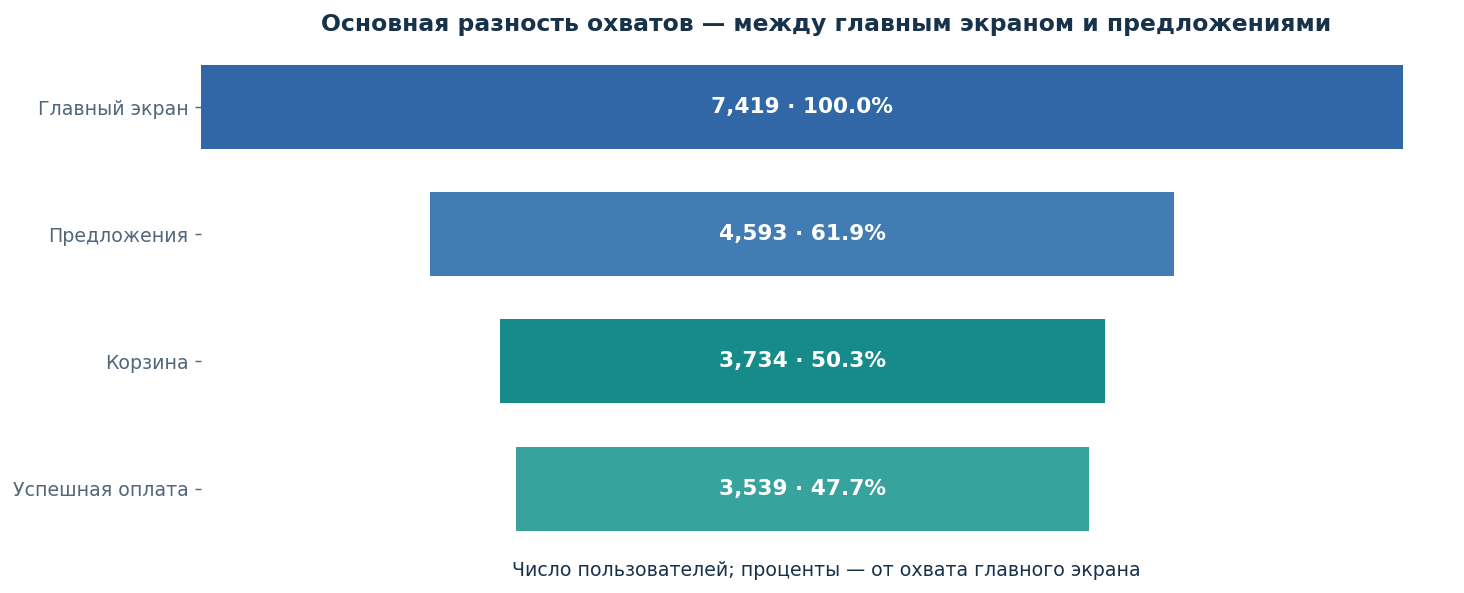

In [12]:
STEPS = ['MainScreenAppear', 'OffersScreenAppear', 'CartScreenAppear', 'PaymentScreenSuccessful']
EVENTS = STEPS + ['Tutorial']
funnel = event_summary.reindex(STEPS)[['users']].copy()
funnel['step_ratio'] = funnel['users'] / funnel['users'].shift(1)
funnel['from_main'] = funnel['users'] / funnel['users'].iloc[0]
funnel['audience_difference'] = funnel['users'].shift(1) - funnel['users']
funnel['loss_ratio'] = 1 - funnel['step_ratio']
table(funnel.rename(index=EVENT_LABELS, columns={
    'users': 'Пользователей', 'step_ratio': 'К предыдущему охвату',
    'from_main': 'К охвату главного', 'audience_difference': 'Разность охватов',
    'loss_ratio': 'Относительная разность',
}), {'Пользователей': '{:,.0f}', 'К предыдущему охвату': '{:.2%}',
     'К охвату главного': '{:.2%}', 'Разность охватов': '{:,.0f}',
     'Относительная разность': '{:.2%}'}, 'Агрегатная воронка охвата')

fig, ax = plt.subplots(figsize=(11.5, 4.8))
counts = funnel['users'].to_numpy()
left = (counts[0] - counts) / 2
ax.barh(np.arange(4), counts, left=left,
        color=[COLORS['blue'], '#417CB4', COLORS['teal'], '#37A39C'], height=0.66)
for i, (count, ratio) in enumerate(zip(counts, funnel['from_main'])):
    ax.text(counts[0] / 2, i, f'{count:,} · {ratio:.1%}', ha='center', va='center',
            color='white', fontsize=12, fontweight='bold')
ax.set(yticks=np.arange(4), yticklabels=[EVENT_LABELS[e] for e in STEPS],
       title='Основная разность охватов — между главным экраном и предложениями',
       xlabel='Число пользователей; проценты — от охвата главного экрана')
ax.invert_yaxis()
ax.set_xlim(0, counts[0] * 1.04)
ax.grid(visible=False)
ax.spines[['left', 'bottom']].set_visible(False)
ax.set_xticks([])
finish(fig)

Отношения соседних охватов составляют **61,91% → 81,30% → 94,78%**. Наибольшая разность — между главным экраном и предложениями: **2 826 пользователей**, или **38,09%** от охвата главного экрана. Отношение оплаты к главному экрану — **3 539 / 7 419 = 47,70%**.

Однако 47,70% нельзя буквально назвать долей посетителей главного экрана, которые затем оплатили: аудитории не полностью вложены. Например, у части оплативших главный экран не зарегистрирован внутри окна. Разность охватов также не равна точному числу людей, покинувших приложение на шаге.

### 4.3. Проверка пути конкретных пользователей

Дополнительно построим последовательную воронку: для каждого пользователя ищем первое событие Main, затем **любое** Offers не раньше него, затем Cart и Payment по тому же правилу. Повторные попытки разрешены; не ограничиваемся первыми событиями каждого типа.

Точность времени — одна секунда, поэтому допускаем одинаковые метки соседних шагов. Порядок действий внутри одной секунды восстановить нельзя. Это путь внутри всего рабочего окна, а не внутри сессии: идентификатора сессии в данных нет.

In [13]:
event_sets = {event: set(analysis.loc[analysis['event_name'].eq(event), 'user_id']) for event in STEPS}
nesting = pd.DataFrame({
    'Следующее событие без предыдущего': [len(event_sets[b] - event_sets[a])
                                         for a, b in zip(STEPS, STEPS[1:])],
}, index=['Главный → предложения', 'Предложения → корзина', 'Корзина → оплата'])
table(nesting, caption='Почему простые отношения охватов не равны индивидуальным переходам')

ordered_counts = np.zeros(len(STEPS), dtype=int)
for _, user_log in analysis.groupby('user_id', sort=False):
    previous_time = -np.inf
    for i, event in enumerate(STEPS):
        times = np.sort(user_log.loc[user_log['event_name'].eq(event), 'event_timestamp'].to_numpy())
        next_index = np.searchsorted(times, previous_time, side='left')
        if next_index == len(times):
            break
        previous_time = times[next_index]
        ordered_counts[i] += 1

ordered_funnel = pd.DataFrame({'Охват события': counts, 'Последовательно': ordered_counts},
                             index=[EVENT_LABELS[e] for e in STEPS])
ordered_funnel['Переход последовательно'] = (
    ordered_funnel['Последовательно'] / ordered_funnel['Последовательно'].shift())
ordered_funnel['От старта последовательно'] = ordered_counts / ordered_counts[0]
assert np.all(np.diff(ordered_counts) <= 0)
table(ordered_funnel, {'Охват события': '{:,.0f}', 'Последовательно': '{:,.0f}',
                        'Переход последовательно': '{:.2%}', 'От старта последовательно': '{:.2%}'},
      'Сравнение охвата и наблюдаемого порядка действий')

paid_with_main = len(event_sets['PaymentScreenSuccessful'] & event_sets['MainScreenAppear'])
print(f'И главный экран, и оплата в любом порядке: {paid_with_main:,} '
      f'({paid_with_main / counts[0]:.2%} от аудитории главного).')
print(f'Весь путь по времени: {ordered_counts[-1]:,} '
      f'({ordered_counts[-1] / ordered_counts[0]:.2%} от начавших).')

,Следующее событие без предыдущего
Главный → предложения,111
Предложения → корзина,55
Корзина → оплата,5


,Охват события,Последовательно,Переход последовательно,От старта последовательно
Главный экран,"7,419","7,419",—,100.00%
Предложения,"4,593","4,459",60.10%,60.10%
Корзина,"3,734","3,371",75.60%,45.44%
Успешная оплата,"3,539","3,085",91.52%,41.58%


И главный экран, и оплата в любом порядке: 3,441 (46.38% от аудитории главного).
Весь путь по времени: 3,085 (41.58% от начавших).


Наблюдаемая последовательность: **7 419 → 4 459 → 3 371 → 3 085**, итог — **41,58%** начавших. На первом переходе теряется **39,90%**, что подтверждает его приоритет для исследования. Оба события Main и Payment в любом порядке есть у 3 441 пользователя — **46,38%** аудитории главного экрана.

Эти показатели отвечают на разные вопросы: **47,70%** — отношение охватов, **46,38%** — пересечение аудиторий, **41,58%** — наблюдаемая цепочка из четырёх шагов по времени. Последовательная воронка может недосчитывать реальные покупки при пропусках телеметрии, альтернативных маршрутах и обрезке пути границами окна.

Практический приоритет — исследовать переход к предложениям: видимость входа в каталог, загрузку экрана и сценарии навигации. Это направления следующей проверки, а не доказанные причины потерь.

<a id="section-5"></a>
## 5. A/A/B-эксперимент

### 5.1. Метрики, знаменатели и план проверок

Группы **246 и 247** видели старый шрифт, **248** — новый. Во всех проверках используем тот же `analysis`, что и для общей аналитики. Уникальные пользователи групп не пересекаются.

Для каждого события метрика — **доля пользователей группы, совершивших его хотя бы раз за рабочее окно**. Знаменатель включает всех наблюдаемых пользователей группы, а не только посетителей предыдущего шага. Повторные действия не увеличивают число успехов.

Проверяем все **пять** событий, включая Tutorial: исключение обучения из основной воронки не означает исключение из эксперимента. Для бизнеса отдельно интерпретируем успешную оплату. Сравнения:

1. 246 против 247 — A/A-диагностика.
2. 246 против 248 — первый контроль и новый шрифт.
3. 247 против 248 — второй контроль и новый шрифт.
4. 246+247 против 248 — объединённый контроль и новый шрифт.

Итого **5 × 4 = 20 проверок**. Они зависимы, поскольку используют общие группы и связанные события. Не будем считать их 20 независимыми подтверждениями результата.

,246: пользователей,246: доля,247: пользователей,247: доля,248: пользователей,248: доля
Главный экран,"2,450",98.63%,"2,476",98.53%,"2,493",98.27%
Предложения,"1,542",62.08%,"1,520",60.49%,"1,531",60.35%
Корзина,"1,266",50.97%,"1,238",49.26%,"1,230",48.48%
Успешная оплата,"1,200",48.31%,"1,158",46.08%,"1,181",46.55%
Обучение,278,11.19%,283,11.26%,279,11.00%


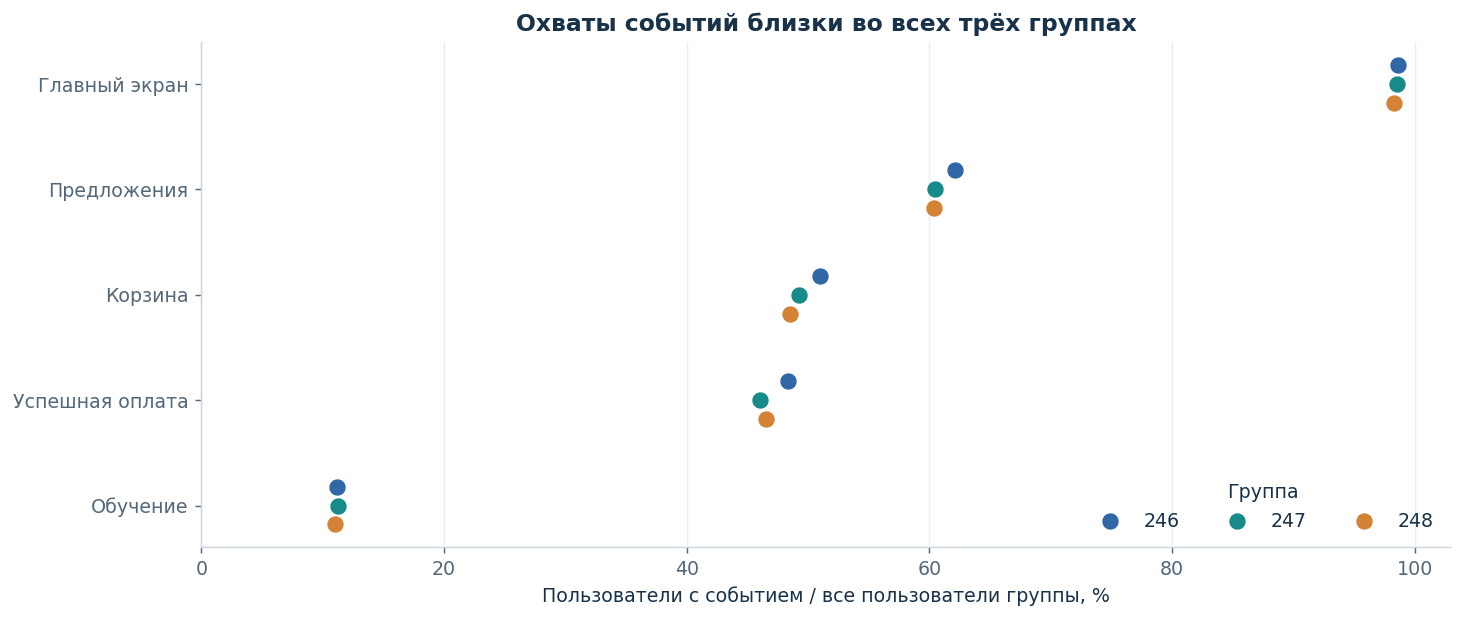

In [14]:
group_sizes = analysis.groupby('experiment_id')['user_id'].nunique().reindex([246, 247, 248])
successes = (analysis.pivot_table(index='event_name', columns='experiment_id',
                                 values='user_id', aggfunc='nunique', fill_value=0)
             .reindex(index=EVENTS, columns=[246, 247, 248]))
rates = successes.div(group_sizes, axis=1)
group_event_report = pd.DataFrame(index=EVENTS)
for group in [246, 247, 248]:
    group_event_report[f'{group}: пользователей'] = successes[group]
    group_event_report[f'{group}: доля'] = rates[group]
formats = {f'{g}: пользователей': '{:,.0f}' for g in [246, 247, 248]}
formats.update({f'{g}: доля': '{:.2%}' for g in [246, 247, 248]})
table(group_event_report.rename(index=EVENT_LABELS), formats,
      'Пользователи с событием / все пользователи группы: 2 484, 2 513 и 2 537')

fig, ax = plt.subplots(figsize=(11.5, 5))
y = np.arange(len(EVENTS))
for offset, group in zip([-0.18, 0, 0.18], [246, 247, 248]):
    ax.scatter(rates[group] * 100, y + offset, s=65, color=GROUP_COLORS[group], label=f'{group}')
ax.set(yticks=y, yticklabels=[EVENT_LABELS[e] for e in EVENTS], xlim=(0, 103),
       xlabel='Пользователи с событием / все пользователи группы, %',
       title='Охваты событий близки во всех трёх группах')
ax.invert_yaxis()
ax.grid(axis='y', visible=False)
ax.legend(title='Группа', ncol=3, loc='lower right')
finish(fig)

Самое популярное событие — **MainScreenAppear**. Его совершили **2 450 из 2 484** пользователей группы 246 (**98,63%**) и **2 476 из 2 513** группы 247 (**98,53%**). Разница долей мала, но статистический вывод делаем по критерию, а не по визуальной близости.

### 5.2. Гипотезы и статистический критерий

Для каждой пары групп и каждого события:

- **H₀:** вероятности совершить событие в сравниваемых группах равны: p(A) = p(B).
- **H₁:** вероятности различаются: p(A) ≠ p(B).

Применяем **двусторонний z-тест двух долей с объединённой оценкой вероятности при H₀**. На уровне пользователя исход бинарный; группы не пересекаются. Число пользователей с событием и без него достаточно велико для нормального приближения; это проверяется в коде.

Уровень значимости семейства задаём **α = 0,05**. Для контроля вероятности хотя бы одного ложного отклонения в 20 проверках используем **Бонферрони**: порог для каждой проверки **0,05 / 20 = 0,0025**. Поправка допустима и при зависимости проверок. Она меняет порог α, а не уменьшает p-value. Эквивалентно можно сравнить `min(20 × p, 1)` с 0,05.

Рядом покажем решения при исходном 0,05 и скорректированном 0,0025. 95%-е интервалы ниже описывают точность отдельных эффектов; они не являются одновременными интервалами для всех 20 сравнений.

In [15]:
ALPHA_FAMILY = 0.05
COMPARISONS = [
    ('246 → 247', [246], [247]),
    ('246 → 248', [246], [248]),
    ('247 → 248', [247], [248]),
    ('246+247 → 248', [246, 247], [248]),
]
N_TESTS = len(EVENTS) * len(COMPARISONS)
ALPHA_CORRECTED = ALPHA_FAMILY / N_TESTS

def proportion_test(event, first_groups, second_groups):
    """Разность — вторая группа минус первая; двусторонний pooled z-тест."""
    n1 = int(group_sizes.loc[first_groups].sum())
    n2 = int(group_sizes.loc[second_groups].sum())
    x1 = int(successes.loc[event, first_groups].sum())
    x2 = int(successes.loc[event, second_groups].sum())
    assert min(x1, n1 - x1, x2, n2 - x2) >= 5
    p1, p2 = x1 / n1, x2 / n2
    pooled = (x1 + x2) / (n1 + n2)
    null_se = np.sqrt(pooled * (1 - pooled) * (1 / n1 + 1 / n2))
    z = (p2 - p1) / null_se
    p_value = 2 * stats.norm.sf(abs(z))
    # Индивидуальный 95% Wald-интервал для разности двух долей.
    effect_se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    margin = stats.norm.ppf(0.975) * effect_se
    return {'n1': n1, 'n2': n2, 'x1': x1, 'x2': x2, 'p1': p1, 'p2': p2,
            'difference': p2 - p1, 'z': z, 'p_value': p_value,
            'se': effect_se, 'ci_low': p2 - p1 - margin, 'ci_high': p2 - p1 + margin}

results = []
for label, first_groups, second_groups in COMPARISONS:
    for event in EVENTS:
        row = proportion_test(event, first_groups, second_groups)
        row.update({'comparison': label, 'event': event})
        results.append(row)
tests = pd.DataFrame(results)
tests['p_bonferroni'] = np.minimum(tests['p_value'] * N_TESTS, 1)
tests['reject_raw'] = tests['p_value'] < ALPHA_FAMILY
tests['reject_corrected'] = tests['p_value'] < ALPHA_CORRECTED
assert len(tests) == N_TESTS == 20
assert (tests['reject_corrected'] == (tests['p_bonferroni'] < ALPHA_FAMILY)).all()
print(f'Проверок: {N_TESTS}; общий α = {ALPHA_FAMILY}; порог после поправки = {ALPHA_CORRECTED}.')
print('Минимальное число успехов / неуспехов в одной группе:',
      int(min(tests['x1'].min(), (tests['n1']-tests['x1']).min(),
              tests['x2'].min(), (tests['n2']-tests['x2']).min())))

def show_tests(labels, caption):
    view = tests.loc[tests['comparison'].isin(labels)].copy()
    view['event'] = view['event'].map(EVENT_LABELS)
    view['difference_pp'] = view['difference'] * 100
    view['raw_decision'] = view['reject_raw'].map({True: 'Да', False: 'Нет'})
    view['corrected_decision'] = view['reject_corrected'].map({True: 'Да', False: 'Нет'})
    view = view.set_index(['comparison', 'event'])[
        ['p1', 'p2', 'difference_pp', 'p_value', 'raw_decision', 'corrected_decision']]
    view.index.names = ['Сравнение', 'Событие']
    table(view.rename(columns={
        'p1': 'Доля A', 'p2': 'Доля B', 'difference_pp': 'B − A, п.п.',
        'p_value': 'p-value', 'raw_decision': 'H₀ отклонена: 0,05',
        'corrected_decision': 'H₀ отклонена: 0,0025',
    }), {'Доля A': '{:.2%}', 'Доля B': '{:.2%}', 'B − A, п.п.': '{:+.2f}', 'p-value': '{:.4f}'}, caption)

Проверок: 20; общий α = 0.05; порог после поправки = 0.0025.
Минимальное число успехов / неуспехов в одной группе: 34


### 5.3. A/A: две группы со старым шрифтом

In [16]:
show_tests(['246 → 247'], 'A/A: 5 событий; вторая доля — группа 247')

Для самого популярного события `p = 0,7571`. Для остальных четырёх событий различия также не обнаружены: все p-value выше 0,05 и, следовательно, выше 0,0025.

A/A-проверка **не выявила противоречий** сопоставимости контрольных групп по выбранным метрикам. Это поддерживает использование объединённого контроля вместе с проверкой отсутствия пересечений, но не доказывает идеальность механизма разбиения или точное равенство групп.

### 5.4. Новый шрифт против каждого контроля

In [17]:
show_tests(['246 → 248', '247 → 248'],
           'A/B: новый шрифт отдельно против каждой контрольной группы')

Ни для одного события различия не обнаружены даже при исходном **α = 0,05**. Минимальный p-value — **0,0784** для корзины в сравнении 246 и 248; доля экспериментальной группы ниже на **2,48 п.п.** Эта оценка сама по себе не является статистически значимым результатом при выбранном уровне.

Если использовать α = 0,10 без поправки, это сравнение пересекло бы порог. Выбор более удобного α после просмотра результатов недопустим. При истинных H₀ каждая отдельная проверка с α = 0,10 имеет до 10% вероятности ложного отклонения; при множестве проверок общий риск выше. Порог 0,0025 выбран заранее для всего семейства из 20 тестов.

### 5.5. Новый шрифт против объединённого контроля

Контроль содержит **4 997 уникальных пользователей**. Поскольку 246 и 247 не пересекаются, их числители и знаменатели можно сложить. Исходные номера групп в логе сохраняем.

In [18]:
show_tests(['246+247 → 248'], 'A/B: объединённый контроль против нового шрифта')

decisions = pd.DataFrame({
    'Уровень / правило': ['Без поправки: α = 0,10', 'Без поправки: α = 0,05',
                         'Бонферрони: α = 0,0025'],
    'Проверок': [len(tests)] * 3,
    'Отклонено H₀': [int((tests['p_value'] < 0.10).sum()),
                      int(tests['reject_raw'].sum()), int(tests['reject_corrected'].sum())],
}).set_index('Уровень / правило')
table(decisions, caption='Все 20 проверок: как выбор порога влияет на вывод')

,Проверок,Отклонено H₀
Уровень / правило,,
"Без поправки: α = 0,10",20,1
"Без поправки: α = 0,05",20,0
"Бонферрони: α = 0,0025",20,0


В объединённом сравнении значимых различий также нет. Минимальное p-value среди всех 20 проверок — 0,0784; скорректированные p-value Бонферрони для всех проверок равны 1 после ограничения сверху. Решение об отсутствии обнаруженных различий сохраняется после поправки, а не выводится из предположения о ней.

### 5.6. Величина эффекта и точность вывода

Одного p-value недостаточно для решения. Оценим разность вероятностей события между 248 и объединённым контролем. Индивидуальные 95%-е интервалы показывают неопределённость оценок. Для согласованного отображения множественности добавим более широкие интервалы **99,75%**: по неравенству Бонферрони они дают приближённое одновременное покрытие не ниже 95% для семейства 20 сравнений. Интервалы нормальные, поэтому покрытие приближённое.

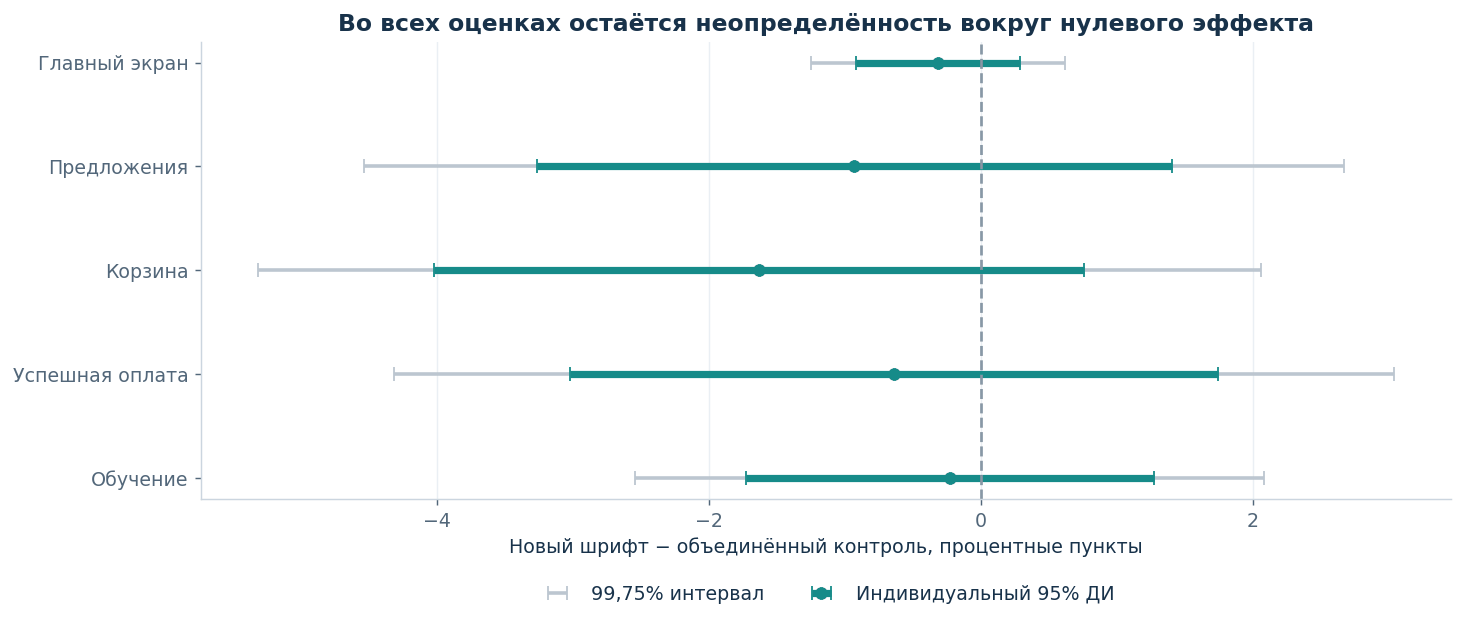

Оплата: контроль 2,358/4,997 = 47.188%; новый шрифт 1,181/2,537 = 46.551%.
Разность: -0.637 п.п.; 95% ДИ [-3.021; +1.747] п.п.; p = 0.600429.


In [19]:
pooled_effects = tests.loc[tests['comparison'].eq('246+247 → 248')].set_index('event').reindex(EVENTS)
family_critical = stats.norm.ppf(1 - ALPHA_CORRECTED / 2)
fig, ax = plt.subplots(figsize=(11.5, 5.1))
for y, (_, row) in enumerate(pooled_effects.iterrows()):
    effect = row['difference'] * 100
    ax.errorbar(effect, y, xerr=family_critical * row['se'] * 100, fmt='none',
                color='#BCC6D0', capsize=4, linewidth=2.0,
                label='99,75% интервал' if y == 0 else None)
    ax.errorbar(effect, y, xerr=stats.norm.ppf(0.975) * row['se'] * 100, fmt='o',
                color=COLORS['teal'], capsize=4, linewidth=4,
                label='Индивидуальный 95% ДИ' if y == 0 else None)
ax.axvline(0, color=COLORS['gray'], linestyle='--')
ax.set(yticks=np.arange(len(EVENTS)), yticklabels=[EVENT_LABELS[e] for e in EVENTS],
       xlabel='Новый шрифт − объединённый контроль, процентные пункты',
       title='Во всех оценках остаётся неопределённость вокруг нулевого эффекта')
ax.invert_yaxis()
ax.grid(axis='y', visible=False)
ax.legend(ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.15))
finish(fig)

payment = pooled_effects.loc['PaymentScreenSuccessful']
print(f'Оплата: контроль {int(payment["x1"]):,}/{int(payment["n1"]):,} = {payment["p1"]:.3%}; '
      f'новый шрифт {int(payment["x2"]):,}/{int(payment["n2"]):,} = {payment["p2"]:.3%}.')
print(f'Разность: {payment["difference"] * 100:+.3f} п.п.; '
      f'95% ДИ [{payment["ci_low"] * 100:+.3f}; {payment["ci_high"] * 100:+.3f}] п.п.; '
      f'p = {payment["p_value"]:.6f}.')

Успешная оплата зарегистрирована у **1 181 из 2 537 (46,55%)** пользователей нового шрифта и **2 358 из 4 997 (47,19%)** объединённого контроля. Разность — **−0,64 п.п.**, индивидуальный 95% ДИ **[−3,02; +1,75] п.п.**, `p = 0,6004`.

Таким образом, **преимущество нового шрифта не обнаружено**, но данные также не исключают практически значимого снижения конверсии. Нельзя заключить, что шрифты эквивалентны или что новый гарантированно не ухудшает результат. Для проверки допустимого ухудшения нужно заранее задать бизнес-порог и спланировать тест на не меньшую эффективность либо эквивалентность.

Имеющийся лог содержит только активных зарегистрированных пользователей. Полного списка назначенных участников, момента первого показа шрифта и пользователей без событий нет. Это ограничивает перенос результата на всю аудиторию и проверку корректности дизайна эксперимента.

<a id="section-6"></a>
## 6. Выводы и решение

### Данные и качество

Из 244 126 строк удалены 413 полных дублей. Временное отсечение до 1 августа оставило **240 887 событий и 7 534 пользователя**; потеря составила 1,16% событий и 0,23% пользователей после дедупликации. Основной поток стабильно наблюдается с 1 августа во всех группах; последний день заканчивается в 21:15:17 UTC и не является полными сутками.

Все дальнейшие разделы используют одно окно. В нём представлены три группы: 246 — 2 484 пользователя, 247 — 2 513, 248 — 2 537. Пересечений идентификаторов между группами нет на всём доступном логе.

### Путь к покупке

Основная цепочка — главный экран → предложения → корзина → успешная оплата. Обучение анализируется отдельно от неё. Отношения охватов соседних шагов — **61,91%, 81,30% и 94,78%**. Самая большая разность охватов — **38,09%** между главным экраном и предложениями.

Отношение охватов оплаты и главного экрана — **47,70%**, но оно не проверяет порядок действий. Наблюдаемый путь через все четыре события по времени проходят **3 085 пользователей, или 41,58% начавших**; на первом переходе в этой воронке теряется **39,90%**. Вывод о приоритете первого перехода сохраняется при обоих способах расчёта.

### Результат A/A/B

Выполнены **20 двусторонних z-тестов**: пять событий для A/A, нового шрифта против каждого контроля и против объединённого контроля. При семейном α = 0,05 и поправке Бонферрони порог на одну проверку равен **0,0025**. Значимых различий нет ни после поправки, ни при исходном α = 0,05. A/A не выявил различий по выбранным метрикам, но не доказал безупречность рандомизации.

По оплате новый шрифт отличается от объединённого контроля на **−0,64 п.п.** с индивидуальным 95% ДИ **[−3,02; +1,75] п.п.** Статистически подтверждённого победителя нет. Утверждение «смена шрифта никак не влияет» эти данные не обосновывают.

### Решение для команды

| Направление | Что делать | На чём основано |
|:--|:--|:--|
| Шрифты | Если единственный критерий — рост покупок, сохранить старый вариант: доказанного преимущества нового нет. | Эксперимент не выявил повышения конверсии; интервалы допускают ухудшение. |
| Дальнейшая проверка нового дизайна | До следующего запуска задать допустимое снижение, целевой эффект, длительность и объём выборки; учитывать причины обновления дизайна отдельно. | Отсутствие значимости не равно доказанной безопасности или эквивалентности. |
| Воронка | В первую очередь исследовать переход с главного экрана к предложениям. Проверить навигацию, загрузку экрана и события телеметрии. | На этом переходе крупнейшая потеря и по охватам, и в наблюдаемой последовательности. |
| Измерение | Уточнить границы выгрузки, события показа варианта, правила назначения групп и сессии; собирать полное заранее заданное окно. | Обрезка периода и отсутствие данных о назначенных неактивных участниках ограничивают выводы. |

Проверенные данные позволяют определить приоритет улучшения пути к покупке. Для окончательного решения о новом шрифте важны заранее заданные бизнес-критерии и точность, достаточная для их проверки.